# Data Split — Group 3

Builds the train / validation / test partition and the cross-validation folds shared by every downstream fine-tuning and evaluation notebook.

## 1. Setup

In [15]:
import json
import math
import re
from pathlib import Path

import ijson
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedGroupKFold

DATA_DIR   = Path('../../data/1_raw')
OUTPUT_DIR = Path('../../data/2_processed')
OUTPUT_DIR.mkdir(exist_ok=True)

GROUP3 = ['TRC', 'TRE', 'TRG', 'TRL', 'TRP']

TRAIN_FRAC = 0.75
VAL_FRAC   = 0.10
TEST_FRAC  = 0.15

assert abs(TRAIN_FRAC + VAL_FRAC + TEST_FRAC - 1.0) < 1e-9

N_FOLDS = 6
SEED    = 42

### 1.1 Load Group 3 Records

Only the fields this notebook needs (`ImportJurisprudenciaId`, `NumeroProcesso`, `Sumario`, `Observacoes`) are streamed in via `ijson`.

In [16]:
NEEDED_FIELDS = ['ImportJurisprudenciaId', 'NumeroProcesso', 'Sumario', 'Observacoes']

def load_court(court):
    records = []
    with open(DATA_DIR / f"{court}.json", "rb") as f:
        for rec in ijson.items(f, "item"):
            record_dict = {}
            for field in NEEDED_FIELDS:
                record_dict[field] = rec.get(field)
            records.append(record_dict)

    df = pd.DataFrame(records)
    df["source"] = court
    return df

all_data = pd.concat([load_court(c) for c in GROUP3], ignore_index=True)
print(f'Records loaded : {len(all_data):,}')
all_data['source'].value_counts().rename('records').to_frame()


Records loaded : 35,815


,records
source,
TRL,12145
TRE,7576
TRG,6714
TRP,4825
TRC,4555


### 1.2 Parse `Decisao` and Keep Only Labelled Records

Records where `Observacoes` is absent or the regex does not match are dropped.

In [17]:
def parse_decisao(obs):
    if not obs or not isinstance(obs, str):
        return None

    m = re.search(r"Decis[aã]o:\s*(.+)", obs)
    if m:
        return m.group(1).split("\n")[0].strip()

    return None

all_data['Decisao'] = all_data['Observacoes'].apply(parse_decisao)

before = len(all_data)
all_data = all_data[all_data['Decisao'].notna()].reset_index(drop=True)
after = len(all_data)

print(f'Records loaded (Group 3)  : {before:,}')
print(f'Records with Decisao      : {after:,}  ({after/before*100:.1f}%)')
print(f'Dropped (no Decisao)      : {before - after:,}')
print(f'Unique Decisao values     : {all_data["Decisao"].nunique():,}')

Records loaded (Group 3)  : 35,815
Records with Decisao      : 15,484  (43.2%)
Dropped (no Decisao)      : 20,331
Unique Decisao values     : 916


## 2. Data-Contamination Check — Duplicate Grouping

A non-trivial fraction of `Sumario` texts are shared across records, and records can share the same `NumeroProcesso` (quantified below).

In [18]:
def normalise(text):
    if not isinstance(text, str):
        return None
    text = text.lower()
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text or None

all_data['sumario_norm'] = all_data['Sumario'].apply(normalise)

class UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))

    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.parent[ra] = rb

n  = len(all_data)
uf = UnionFind(n)

for key_col in ['sumario_norm', 'NumeroProcesso']:
    for _, idx in all_data.groupby(key_col).indices.items():
        if len(idx) > 1:
            first = idx[0]
            for i in idx[1:]:
                uf.union(first, i)

all_data['group_id'] = pd.factorize(np.array([uf.find(i) for i in range(n)]))[0]

In [19]:
group_sizes = all_data.groupby('group_id').size()
n_groups    = len(group_sizes)
n_multi     = (group_sizes > 1).sum()
records_in_multi = group_sizes[group_sizes > 1].sum()

print(f'Total records          : {n:,}')
print(f'Unique duplicate groups: {n_groups:,}')
print(f'Groups with >1 record  : {n_multi:,}  ({n_multi/n_groups*100:.2f}% of groups)')
print(f'Records inside those   : {records_in_multi:,}  ({records_in_multi/n*100:.2f}% of all records)')
print(f'Largest group size     : {group_sizes.max():,}')

label_span = all_data.groupby('group_id')['Decisao'].nunique()
multi_label_groups = (label_span > 1).sum()
print(f'\nGroups spanning >1 Decisao label: {multi_label_groups:,}')
print('(these are near-duplicate/NumeroProcesso matches with inconsistent labelling; the')
print(' group majority label is used below to decide which stratum the group belongs to)')


Total records          : 15,484
Unique duplicate groups: 15,358
Groups with >1 record  : 114  (0.74% of groups)
Records inside those   : 240  (1.55% of all records)
Largest group size     : 6

Groups spanning >1 Decisao label: 82
(these are near-duplicate/NumeroProcesso matches with inconsistent labelling; the
 group majority label is used below to decide which stratum the group belongs to)


## 3. Stratified Train / Val / Test Split (Group-Aware)

The split is performed at the duplicate-group level, stratified on each group's majority `Decisao` label.

In [20]:
group_label = all_data.groupby('group_id')['Decisao'].agg(lambda s: s.mode().iat[0])
group_size  = all_data.groupby('group_id').size()

groups_df = pd.DataFrame({'Decisao': group_label, 'size': group_size}).reset_index()
print(f'Groups to split : {len(groups_df):,}')

MIN_GROUPS_PER_CLASS = math.ceil(N_FOLDS / TRAIN_FRAC)
print(f'MIN_GROUPS_PER_CLASS = ceil({N_FOLDS} / {TRAIN_FRAC}) = {MIN_GROUPS_PER_CLASS}')

class_group_counts = groups_df['Decisao'].value_counts()
rare_classes = class_group_counts[class_group_counts < MIN_GROUPS_PER_CLASS].index

n_rare_records = all_data['Decisao'].isin(rare_classes).sum()
print(f'\nClasses below floor : {len(rare_classes):,}  (of {class_group_counts.shape[0]:,})')
print(f'Groups dropped      : {groups_df["Decisao"].isin(rare_classes).sum():,}')
print(f'Records dropped     : {n_rare_records:,}  ({n_rare_records/len(all_data)*100:.2f}% of labelled records)')

groups_df = groups_df[~groups_df['Decisao'].isin(rare_classes)].reset_index(drop=True)
all_data  = all_data[all_data['group_id'].isin(groups_df['group_id'])].reset_index(drop=True)

print(f'\nRemaining records : {len(all_data):,}')
print(f'Remaining classes : {all_data["Decisao"].nunique():,}')
print(f'Remaining groups  : {len(groups_df):,}')


Groups to split : 15,358
MIN_GROUPS_PER_CLASS = ceil(6 / 0.75) = 8

Classes below floor : 816  (of 908)
Groups dropped      : 1,223
Records dropped     : 1,236  (7.98% of labelled records)

Remaining records : 14,240
Remaining classes : 109
Remaining groups  : 14,135


In [21]:
train_val_groups, test_groups = train_test_split(
    groups_df, test_size=TEST_FRAC, stratify=groups_df['Decisao'], random_state=SEED,
)
train_groups, val_groups = train_test_split(
    train_val_groups, test_size=VAL_FRAC / (TRAIN_FRAC + VAL_FRAC),
    stratify=train_val_groups['Decisao'], random_state=SEED,
)

split_of_group = pd.concat([
    train_groups['group_id'].to_frame().assign(split='train'),
    val_groups['group_id'].to_frame().assign(split='val'),
    test_groups['group_id'].to_frame().assign(split='test'),
]).set_index('group_id')['split']

all_data['split'] = all_data['group_id'].map(split_of_group)
assert all_data['split'].notna().all(), 'Every record must land in a split.'

print('Group-level split sizes:')
print(f'  train : {len(train_groups):,}')
print(f'  val   : {len(val_groups):,}')
print(f'  test  : {len(test_groups):,}')

print('\nRecord-level split proportions (target 75 / 10 / 15):')
print((all_data['split'].value_counts(normalize=True) * 100).round(2).to_string())


Group-level split sizes:
  train : 10,600
  val   : 1,414
  test  : 2,121

Record-level split proportions (target 75 / 10 / 15):
split
train    74.99
test     15.01
val      10.00


### 3.1 Contamination Re-Check — Post Split (Expected: Zero)

In [22]:
leak_check = all_data.groupby('group_id')['split'].nunique()
n_leaking  = (leak_check > 1).sum()

print(f'Duplicate groups spanning multiple splits : {n_leaking}  (expected: 0)')
assert n_leaking == 0, 'Data contamination detected: a duplicate group spans multiple splits.'
print('No contamination between train / val / test.')


Duplicate groups spanning multiple splits : 0  (expected: 0)
No contamination between train / val / test.


## 4. Class Distribution per Split

Sanity check on the top 20 classes (the bulk of labelled records) to confirm the stratified split preserved per-class proportions across.

In [23]:
top20 = all_data['Decisao'].value_counts().head(20).index

dist = (
    all_data[all_data['Decisao'].isin(top20)]
    .groupby(['Decisao', 'split']).size()
    .unstack(fill_value=0)
    .reindex(columns=['train', 'val', 'test'])
)
dist_pct = dist.div(dist.sum(axis=1), axis=0) * 100
display(dist_pct.round(1))


split,train,val,test
Decisao,,,
ANULADA,74.1,10.1,15.8
APELAÇÃO IMPROCEDENTE,75.2,9.9,14.9
APELAÇÃO PROCEDENTE,75.4,10.0,14.7
CONFIRMADA,75.0,10.0,15.0
CONFIRMADA A DECISÃO RECORRIDA,75.1,10.1,14.9
CONFIRMADA A SENTENÇA,74.7,10.4,14.9
CONFIRMADA POR UNANIMIDADE,74.8,10.1,15.1
CONFIRMAÇÃO,74.8,10.2,15.0
IMPROCEDENTE,75.0,9.9,15.1


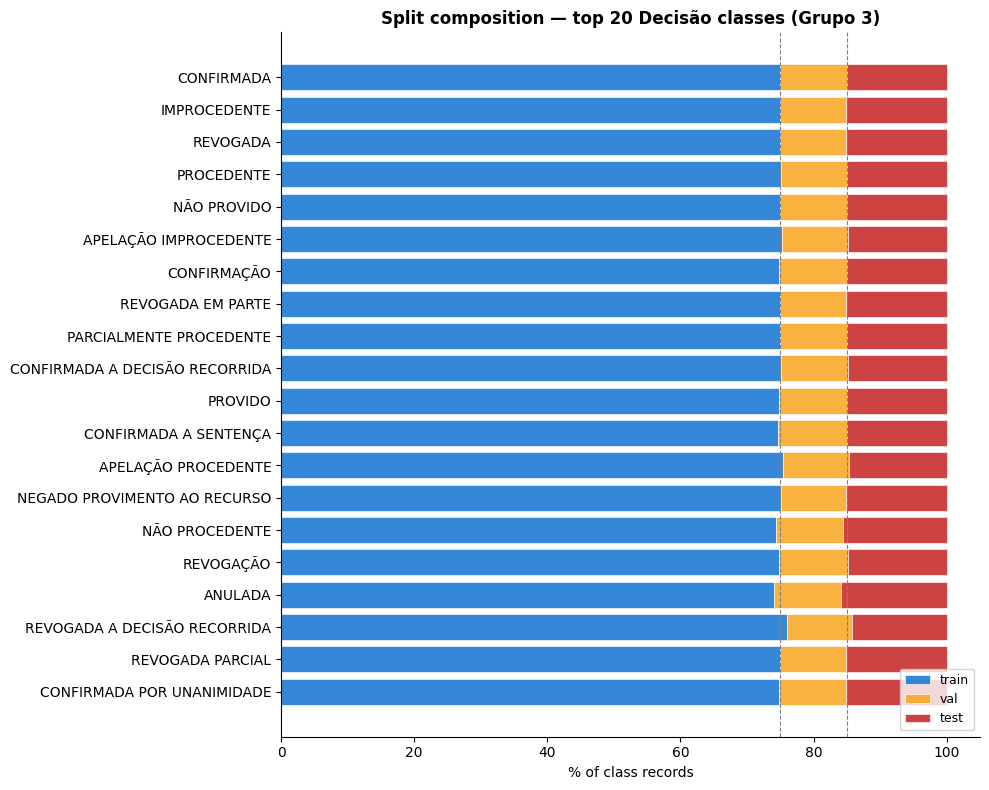

In [24]:
order = dist.sum(axis=1).sort_values().index

fig, ax = plt.subplots(figsize=(10, 8))
lefts = np.zeros(len(order))
colors = {'train': '#1976D2', 'val': '#F9A825', 'test': '#C62828'}

for split in ['train', 'val', 'test']:
    vals = dist_pct.loc[order, split].values
    ax.barh(order, vals, left=lefts, color=colors[split], alpha=0.88,
            edgecolor='white', linewidth=0.5, label=split)
    lefts += vals

ax.set_title('Split composition — top 20 Decisão classes (Grupo 3)', fontsize=12, fontweight='bold')
ax.set_xlabel('% of class records')
ax.axvline(TRAIN_FRAC * 100, color='grey', linestyle='--', linewidth=0.8)
ax.axvline((TRAIN_FRAC + VAL_FRAC) * 100, color='grey', linestyle='--', linewidth=0.8)
ax.legend(fontsize=9, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()


## 5. Stratified 6-Fold Cross-Validation — Train Partition Only

CV folds are assigned only to the train split.

In [25]:
all_data['cv_fold'] = -1

train_mask = all_data['split'] == 'train'
train_idx  = all_data.index[train_mask]
X_train    = all_data.loc[train_idx]

sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

for fold, (_, val_pos) in enumerate(
    sgkf.split(X_train, X_train['Decisao'], groups=X_train['group_id'])
):
    fold_row_idx = train_idx[val_pos]
    all_data.loc[fold_row_idx, 'cv_fold'] = fold

print('Train records per CV fold:')
print(all_data.loc[train_mask, 'cv_fold'].value_counts().sort_index().to_string())


<project>/.venv/lib/python3.13/site-packages/sklearn/model_selection/_split.py:1036: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=6.
  warnings.warn(


Train records per CV fold:
cv_fold
0    1780
1    1780
2    1780
3    1780
4    1779
5    1780


### 5.1 Fold-Level Contamination Re-Check (Expected: Zero)

In [26]:
fold_leak   = all_data[train_mask].groupby('group_id')['cv_fold'].nunique()
n_fold_leak = (fold_leak > 1).sum()

print(f'Train duplicate groups spanning multiple CV folds : {n_fold_leak}  (expected: 0)')
assert n_fold_leak == 0, 'Data contamination detected: a duplicate group spans multiple CV folds.'
print('No contamination between CV folds.')


Train duplicate groups spanning multiple CV folds : 0  (expected: 0)
No contamination between CV folds.


### 5.2 Per-Fold Class Balance (Top 20 Classes)

In [27]:
fold_class_dist = (
    all_data[train_mask & all_data['Decisao'].isin(top20)]
    .groupby(['Decisao', 'cv_fold']).size()
    .unstack(fill_value=0)
)
display(fold_class_dist)


cv_fold,0,1,2,3,4,5
Decisao,,,,,,
ANULADA,18,17,17,17,17,17
APELAÇÃO IMPROCEDENTE,68,69,68,69,68,68
APELAÇÃO PROCEDENTE,26,27,27,26,27,26
CONFIRMADA,428,428,428,428,427,428
CONFIRMADA A DECISÃO RECORRIDA,47,47,47,48,47,47
CONFIRMADA A SENTENÇA,28,28,27,27,28,27
CONFIRMADA POR UNANIMIDADE,14,15,15,15,15,15
CONFIRMAÇÃO,60,60,60,60,60,60
IMPROCEDENTE,234,234,234,233,234,234


## 6. Export

The id → split → fold mapping is written to `../../data/2_processed/` as a UTF-8 CSV. Every downstream notebook (`06` onward) should join.

In [28]:
EXPORT_COLS = [
    'ImportJurisprudenciaId', 'source', 'NumeroProcesso', 'Decisao',
    'group_id', 'split', 'cv_fold',
]

export_path = OUTPUT_DIR / 'splits_grupo3.csv'
all_data[EXPORT_COLS].to_csv(export_path, index=False, encoding='utf-8')
print(f'Exported : {export_path}  ({len(all_data):,} rows)')

summary = {
    'n_records': int(len(all_data)),
    'n_groups': int(all_data['group_id'].nunique()),
    'n_classes': int(all_data['Decisao'].nunique()),
    'split_sizes': all_data['split'].value_counts().to_dict(),
    'split_fractions': {'train': TRAIN_FRAC, 'val': VAL_FRAC, 'test': TEST_FRAC},
    'cv_folds': N_FOLDS,
    'cv_applies_to': 'train split only',
    'seed': SEED,
    'min_groups_per_class': MIN_GROUPS_PER_CLASS,
    'rare_classes_dropped': sorted(rare_classes.tolist()),
}
summary_path = OUTPUT_DIR / 'splits_grupo3_summary.json'
with open(summary_path, 'w', encoding='utf-8') as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print(f'Summary saved -> {summary_path}')


Exported : ../../data/2_processed/splits_grupo3.csv  (14,240 rows)
Summary saved -> ../../data/2_processed/splits_grupo3_summary.json
